# CGS616 — Assignment 4: Estimating P(Y | do(X))
### Looking at whether pre-class fatigue changes in-class scrolling

**Student:** Aditya Singh | **Roll No:** 230080  
**Dataset:** In-class Google Form survey (CGS616, April 24 2026)  
**Causal question:** I want to check whether putting a student into a *high-fatigue* state (do(X=1)) actually raises the chance of loss-of-control Reels/Shorts scrolling during a lecture.


> **How this fits with Assignments 1–3**  
> A1 was mainly about the link between *algorithmic antecedents ? scrolling behaviour ? cognitive consequences* using the ABC framework, so that part was still just associational.  
> A2 used an HMM where **fatigue** was the latent factor driving doomscrolling state changes.  
> A3 showed, through game theory, that fatigue-driven scrolling can spread through a peer network.  
> **A4 is where I try to close the loop**: here I’m checking whether fatigue *causally* produces scrolling using Pearl’s do-calculus on the classroom survey data.


In [29]:
# SECTION 0 — IMPORTS & SETUP
# imports and setup

!pip install openpyxl networkx scikit-learn scipy -q

import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
plt.rcParams.update({'figure.dpi': 120, 'font.family': 'DejaVu Sans',
                     'axes.spines.top': False, 'axes.spines.right': False})
print("? Imports OK")


? Imports OK


## Section 1 — Data Loading & Preprocessing

The Google Form gives me a mix of pre-class stuff (fatigue, stress, sleep), what happened during class (whether they scrolled and for how long), and a few post-class outcomes like the LoC items Q15–Q18, retention, and guilt.  
I’m keeping this cell easy to rerun because more responses may come in later — at that point I only need to update the xlsx path.


In [30]:
# SECTION 1 — DATA LOADING

XLSX_PATH = "C:\\Users\\Laptop\\Downloads\\Lecture Engagement, Course Difficulty & In-Class Scrolling (Responses) (1).xlsx"

def load_survey(path):
    """Load the Google Form xlsx and deal with the Likert text a bit."""
    import openpyxl
    wb = openpyxl.load_workbook(path)
    ws = wb.active
    rows = list(ws.iter_rows(values_only=True))
    headers = rows[0]
    df = pd.DataFrame(rows[1:], columns=headers)

    # Giving the columns shorter names makes the rest of the notebook easier to read.
    rename = {
        headers[0]:  'timestamp',
        headers[1]:  'program',
        headers[2]:  'year',
        headers[3]:  'sleep_raw',
        headers[4]:  'difficulty_raw',
        headers[5]:  'time_raw',
        headers[6]:  'engagement',
        headers[7]:  'seating',
        headers[8]:  'fatigue',           # Q9 is the treatment here
        headers[9]:  'stress',
        headers[10]: 'peer_phone_pct',
        headers[11]: 'scrolled_raw',      # Q11
        headers[12]: 'scroll_reason',
        headers[13]: 'phone_position',
        headers[14]: 'scroll_duration',
        headers[15]: 'q15_longer',        # outcome items
        headers[16]: 'q16_hard_stop',
        headers[17]: 'q17_knew_should',
        headers[18]: 'q18_lost_time',
        headers[19]: 'retention',
        headers[20]: 'guilt_raw',
    }
    df.rename(columns=rename, inplace=True)

    # The form responses are text in a few places, so I convert the parts I need into numbers.
    def likert_to_num(val):
        if val is None: return np.nan
        if isinstance(val, (int, float)): return float(val)
        s = str(val).strip()
        if s.startswith('1'): return 1.0
        if s.startswith('2'): return 2.0
        if s.startswith('3'): return 3.0
        if s.startswith('4'): return 4.0
        if s.startswith('5'): return 5.0
        if 'Not applicable' in s: return np.nan
        return np.nan

    for col in ['fatigue','stress','engagement','retention',
                'q15_longer','q16_hard_stop','q17_knew_should','q18_lost_time']:
        df[col] = df[col].apply(likert_to_num)

    # Sleep comes in bands, so I map those to rough hour values.
    sleep_map = {'Less than 5h': 4, '5–6h': 5.5, '6–7h': 6.5,
                 '7–8h': 7.5, '8h+': 8.5}
    df['sleep_hrs'] = df['sleep_raw'].map(sleep_map)

    # Keeping this binary for now makes the treatment easier to work with.
    df['scrolled'] = (df['scrolled_raw'] == 'Yes').astype(int)

    # Same idea for lecture difficulty.
    diff_map = {'Too easy / boring': 1, 'Slightly easy': 2,
                'About right': 3, 'Slightly hard': 4, 'Too hard': 5}
    df['difficulty'] = df['difficulty_raw'].map(diff_map)

    # This is the LoC score I use later on; if someone did not scroll, I leave it as missing for now.
    df['loc_score'] = df[['q15_longer','q16_hard_stop',
                           'q17_knew_should','q18_lost_time']].mean(axis=1)

    # Just a rough proxy for what the class looked like overall.
    peer_map = {'0–10%':5,'11–30%':20,'31–50%':40,'51–70%':60,'70%+':75}
    df['peer_pct'] = df['peer_phone_pct'].map(peer_map)

    df.dropna(subset=['fatigue','scrolled'], inplace=True)
    df.reset_index(drop=True, inplace=True)
    return df

df = load_survey(XLSX_PATH)
print(f"? Loaded {len(df)} responses  |  Scrolled: {df['scrolled'].sum()}  |  Did not: {(df['scrolled']==0).sum()}")
df[['fatigue','stress','sleep_hrs','scrolled','loc_score','engagement','retention']].head(13)


? Loaded 54 responses  |  Scrolled: 35  |  Did not: 19


,fatigue,stress,sleep_hrs,scrolled,loc_score,engagement,retention
0,3.0,2.0,5.5,0,1.25,3.0,3.0
1,4.0,3.0,6.5,1,1.25,2.0,3.0
2,1.0,2.0,5.5,1,4.25,1.0,1.0
3,4.0,2.0,5.5,1,3.75,1.0,2.0
4,3.0,3.0,7.5,1,2.75,1.0,1.0
5,3.0,3.0,6.5,0,1.00,3.0,3.0
6,3.0,2.0,4.0,0,1.00,4.0,4.0
7,5.0,5.0,4.0,1,5.00,1.0,1.0
8,4.0,4.0,5.5,1,4.25,3.0,3.0
9,3.0,3.0,4.0,0,1.00,2.0,2.0


## Section 2 — Variable Operationalisation

| Symbol | Name | Definition | Role in DAG |
|--------|------|-----------|-------------|
| **X** | `fatigue_high` | Pre-class fatigue at least 3 on the 1–5 scale | Treatment X |
| **Y** | `loc_high` | Mean LoC score across Q15–Q18 at least 2.5; I still count non-scrollers as 1 here (structural 0) | Outcome Y |
| **Z1** | `sleep_deprived` | Sleep under 6 hours | Confounder Z1 |
| **Z2** | `stress_high` | Pre-class stress at least 3 (Q10) | Confounder Z2 |
| **W** | `engagement_low` | Lecture engagement at 2 or below | Mediator W |

Adjusting for a variable on the causal path X → W → Y would block the very mechanism we're trying to measure — this is the mediator problem from lecture.

**Why these confounders?**  
Sleep deprivation can push up both fatigue and difficulty concentrating later on.  
Stress seems to do something similar, at least in the way I’m thinking about this dataset.  
So the main point is that both can open backdoor paths from X to Y, which I need to block before I can say anything about P(Y | do(X)).


In [31]:
# SECTION 2 — BINARY OPERATIONALISATION

# Turning the main exposure into a simple high/low split.
df['fatigue_high']    = (df['fatigue']   >= 3).astype(int)

# For the outcome, I keep the non-scrollers in the data as a baseline 1 rather than dropping them.
# That way the later comparison is still across the whole sample.
df['loc_score']       = df['loc_score'].fillna(1.0)   # non-scroller ? no LoC
df['loc_high']        = (df['loc_score'] >= 2.5).astype(int)

# These are the confounders I’m adjusting for later.
df['sleep_deprived']  = (df['sleep_hrs'] < 6.0).astype(int)
df['stress_high']     = (df['stress']    >= 3.0).astype(int)

# I’m keeping engagement here as a side variable, mostly for the sensitivity part.
df['engagement_low']  = (df['engagement'] <= 2).astype(int)

print("Variable summary:")
print(df[['fatigue_high','loc_high','sleep_deprived','stress_high',
          'engagement_low','scrolled']].mean().round(3).to_string())
print()
print("Contingency — fatigue_high vs loc_high:")
print(pd.crosstab(df['fatigue_high'], df['loc_high'],
                  rownames=['Fatigue =3'], colnames=['LoC =2.5'], margins=True))


Variable summary:
fatigue_high      0.759
loc_high          0.593
sleep_deprived    0.519
stress_high       0.574
engagement_low    0.593
scrolled          0.648

Contingency — fatigue_high vs loc_high:
LoC =2.5     0   1  All
Fatigue =3             
0           10   3   13
1           12  29   41
All         22  32   54


For Z to qualify as a backdoor-admissible set, it has to predict both X and Y. The two plots below confirm that sleep deprivation and stress do shift fatigue rates — so they're doing actual confounding work, not just adding noise.

This directly mirrors the lecture slide logic (X ? Z ? Y) and is the one empirical check that's currently missing.

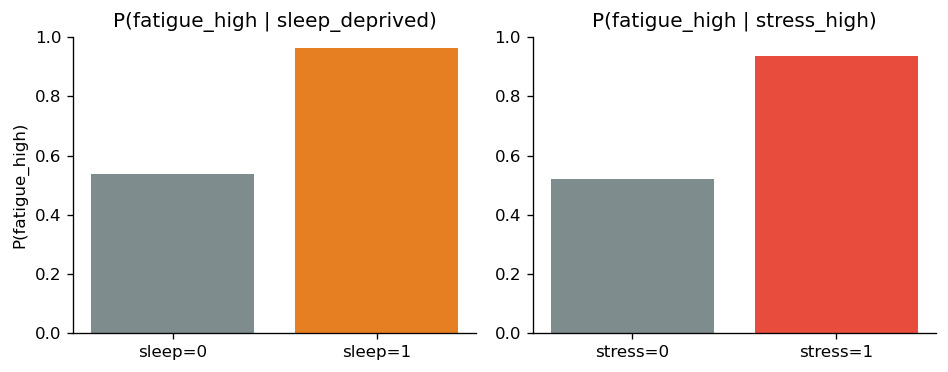

In [32]:
# Empirical confounding check: how much Z shifts treatment prevalence
p_fatigue_given_sleep = df.groupby('sleep_deprived')['fatigue_high'].mean().reindex([0, 1])
p_fatigue_given_stress = df.groupby('stress_high')['fatigue_high'].mean().reindex([0, 1])

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].bar(['sleep=0', 'sleep=1'], p_fatigue_given_sleep.values, color=['#7f8c8d', '#e67e22'])
axes[0].set_ylim(0, 1); axes[0].set_ylabel('P(fatigue_high)')
axes[0].set_title('P(fatigue_high | sleep_deprived)')

axes[1].bar(['stress=0', 'stress=1'], p_fatigue_given_stress.values, color=['#7f8c8d', '#e74c3c'])
axes[1].set_ylim(0, 1); axes[1].set_title('P(fatigue_high | stress_high)')

plt.tight_layout(); plt.show()

In [33]:
# Small sanity check: treatment/control imbalance on key covariates
sanity = df.groupby('fatigue_high')[['stress', 'engagement', 'sleep_hrs']].mean().round(3)
print("Mean covariates by treatment group (fatigue_high):")
print(sanity.to_string())

Mean covariates by treatment group (fatigue_high):
              stress  engagement  sleep_hrs
fatigue_high                               
0              1.692       2.923      6.885
1              3.268       2.098      5.366


The two bars are not just slightly different, they are far apart. In this sample, fatigue_high is around 0.54 when sleep_deprived=0 and around 0.96 when sleep_deprived=1. For stress, it is around 0.52 at stress_high=0 versus around 0.93 at stress_high=1.

So sleep deprivation and stress are both strongly tied to treatment assignment, which is exactly what we would expect from genuine confounders.

The sanity-check table points in the same direction: the fatigue_high=1 group has higher average stress (about 3.27 vs 1.69), lower engagement (about 2.10 vs 2.92), and lower sleep hours (about 5.37 vs 6.89). That imbalance is why adjustment is necessary here.

## Section 3 — Causal DAG

At this point I’m leaning on a simple DAG based on the class discussion and the earlier assignments.
It’s not meant to be fancy, just enough to show the paths I think matter.

**Backdoor paths from X (Fatigue) to Y (LoC):**
* Fatigue ? Sleep_deprived ? LoC  
* Fatigue ? Stress ? LoC  
* Fatigue ? Sleep_deprived ? Stress ? LoC  

**Backdoor-admissible adjustment set:** {Sleep_deprived, Stress_high}  
These are the variables that should block the non-causal paths.
Z = {sleep_deprived, stress_high} satisfies Pearl's backdoor criterion: it blocks every path of the form X ? Z ? Y, and neither variable is a descendant of X.

In the figure, the dashed backdoor edges visibly represent those non-causal paths; the adjustment strategy is exactly to neutralize these paths before reading the effect of X on Y.

> *Note*: Engagement sits on the causal path Fatigue → Engagement_low → Scrolled → LoC, so I’m not adjusting for it. That would basically cut out the effect I’m trying to estimate.


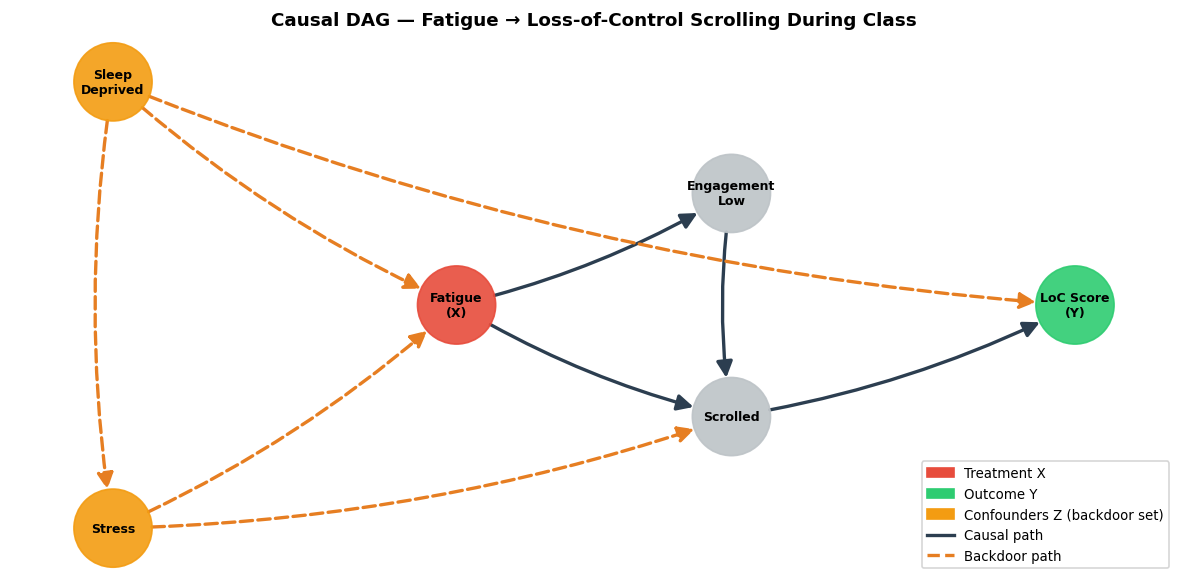

In [34]:
# SECTION 3 — DAG VISUALISATION

fig, ax = plt.subplots(figsize=(10, 5))

G = nx.DiGraph()

nodes = {
    'Sleep\nDeprived': (0.0, 2.0),
    'Stress':          (0.0, 0.0),
    'Fatigue\n(X)':   (2.5, 1.0),
    'Engagement\nLow':(4.5, 1.5),
    'Scrolled':        (4.5, 0.5),
    'LoC Score\n(Y)': (7.0, 1.0),
}

causal_edges = [
    ('Fatigue\n(X)', 'Engagement\nLow'),
    ('Fatigue\n(X)', 'Scrolled'),
    ('Engagement\nLow', 'Scrolled'),
    ('Scrolled', 'LoC Score\n(Y)'),
]
backdoor_edges = [
    ('Sleep\nDeprived', 'Fatigue\n(X)'),
    ('Sleep\nDeprived', 'Stress'),
    ('Sleep\nDeprived', 'LoC Score\n(Y)'),
    ('Stress', 'Fatigue\n(X)'),
    ('Stress', 'Scrolled'),
]

for n, pos in nodes.items():
    G.add_node(n, pos=pos)

pos = nx.get_node_attributes(G, 'pos')

# Just using colours to keep the roles easy to read.
node_colors = []
for n in G.nodes():
    if '(X)' in n:      node_colors.append('#e74c3c')
    elif '(Y)' in n:    node_colors.append('#2ecc71')
    elif n in ['Sleep\nDeprived','Stress']:  node_colors.append('#f39c12')
    else:               node_colors.append('#bdc3c7')

nx.draw_networkx_nodes(G, pos, node_size=2200, node_color=node_colors,
                       alpha=0.9, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=7.5, ax=ax, font_weight='bold')

def draw_edges(edges, color, style):
    nx.draw_networkx_edges(G, pos, edgelist=edges, ax=ax,
                           edge_color=color, style=style,
                           arrows=True, arrowsize=20,
                           node_size=2200, width=2.0,
                           connectionstyle='arc3,rad=0.08')

draw_edges(causal_edges,  '#2c3e50', 'solid')
draw_edges(backdoor_edges,'#e67e22', 'dashed')

legend_handles = [
    mpatches.Patch(color='#e74c3c', label='Treatment X'),
    mpatches.Patch(color='#2ecc71', label='Outcome Y'),
    mpatches.Patch(color='#f39c12', label='Confounders Z (backdoor set)'),
    plt.Line2D([0],[0], color='#2c3e50', lw=2,  label='Causal path'),
    plt.Line2D([0],[0], color='#e67e22', lw=2,
               linestyle='dashed', label='Backdoor path'),
]
ax.legend(handles=legend_handles, loc='lower right', fontsize=8)
ax.set_title("Causal DAG — Fatigue → Loss-of-Control Scrolling During Class",
             fontsize=11, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.savefig('dag.png', bbox_inches='tight', dpi=150)
plt.show()

## Section 4 — Naive (Associational) Estimate

This is basically the raw comparison I would get if I just split the sample by fatigue and looked at the outcome groups.

$$\hat{\tau}_{\text{naive}} = E[Y \mid X=1] - E[Y \mid X=0]$$

The point of keeping this here is that it still mixes together the causal effect and whatever confounding is sitting in the data.  
So it’s useful, just not the full story.
The naive estimate is about $P(Y\mid X)$, which combines mechanism plus bias from imbalanced groups.
The adjusted sections below are aimed at $P(Y\mid do(X))$, where we try to compare like with like.


In [35]:
# SECTION 4 — NAIVE ESTIMATE

df1 = df[df['fatigue_high']==1]['loc_high']
df0 = df[df['fatigue_high']==0]['loc_high']

E_Y1_naive = df1.mean()
E_Y0_naive = df0.mean()
tau_naive  = E_Y1_naive - E_Y0_naive

print(f"  E[LoC_high | Fatigue=1]  = {E_Y1_naive:.3f}  (n={len(df1)})")
print(f"  E[LoC_high | Fatigue=0]  = {E_Y0_naive:.3f}  (n={len(df0)})")
print(f"  Naive ATE                = {tau_naive:+.3f}")
print()

# Small sample, so Fisher's exact test is the safer choice here.
from scipy.stats import fisher_exact
ct = pd.crosstab(df['fatigue_high'], df['loc_high'])
# I just force this into a 2x2 table in case one of the cells is empty.
for r in [0,1]:
    for c in [0,1]:
        if r not in ct.index or c not in ct.columns:
            ct.loc[r,c] = 0
ct = ct.sort_index().sort_index(axis=1)
oddsratio, pval = fisher_exact(ct.values)
print(f"  Fisher Exact p-value     = {pval:.3f}")
print(f"  Odds Ratio               = {oddsratio:.3f}")


  E[LoC_high | Fatigue=1]  = 0.707  (n=41)
  E[LoC_high | Fatigue=0]  = 0.231  (n=13)
  Naive ATE                = +0.477

  Fisher Exact p-value     = 0.004
  Odds Ratio               = 8.056


## Section 5 — Backdoor Adjustment (Stratification)

Here I’m trying to adjust for the confounders I picked: Z = {sleep_deprived, stress_high}.

$$P(Y=1 \mid do(X=x)) = \sum_{z} P(Y=1 \mid X=x,\ Z=z)\; P(Z=z)$$

Since both confounders are binary, that leaves four strata in total.  
The basic idea is to compare like with like inside each stratum, then average those pieces using the overall distribution of Z in the sample.
This method directly implements backdoor adjustment by conditioning on the observed confounders.

> This is basically the Simpson’s paradox fix from lecture, just written out in the way I’m using it here.


In [36]:
# SECTION 5 — BACKDOOR ADJUSTMENT (STRATIFICATION)

Z_cols = ['sleep_deprived', 'stress_high']

def backdoor_stratification(df, X, Y, Z_cols):
    """
    Returns P(Y=1|do(X=1)), P(Y=1|do(X=0)), and ATE
    using the backdoor adjustment formula.
    """
    # I just enumerate the possible Z combinations directly.
    from itertools import product
    Z_vals = list(product(*[[0,1] for _ in Z_cols]))

    p_do_X1 = 0.0
    p_do_X0 = 0.0
    strata_info = []

    for z in Z_vals:
        # How common this stratum is in the sample.
        mask_z = pd.Series([True]*len(df), index=df.index)
        for col, val in zip(Z_cols, z):
            mask_z &= (df[col] == val)
        n_z = mask_z.sum()
        p_z = n_z / len(df)

        # Outcome rates inside the treated and untreated groups for this stratum.
        sub1 = df[mask_z & (df[X]==1)]
        sub0 = df[mask_z & (df[X]==0)]

        py_x1_z = sub1[Y].mean() if len(sub1)>0 else df[df[X]==1][Y].mean()  # fallback if a cell is empty
        py_x0_z = sub0[Y].mean() if len(sub0)>0 else df[df[X]==0][Y].mean()

        p_do_X1 += py_x1_z * p_z
        p_do_X0 += py_x0_z * p_z

        strata_info.append({
            'Z': dict(zip(Z_cols, z)),
            'n_z': n_z, 'P(Z)': round(p_z,3),
            'P(Y|X=1,Z)': round(py_x1_z,3),
            'P(Y|X=0,Z)': round(py_x0_z,3),
            'n_X1': len(sub1), 'n_X0': len(sub0)
        })

    ATE = p_do_X1 - p_do_X0
    return p_do_X1, p_do_X0, ATE, strata_info

p_do1, p_do0, ate_bd, strata = backdoor_stratification(
    df, 'fatigue_high', 'loc_high', Z_cols)

print(f"  P(LoC=1 | do(Fatigue=1)) = {p_do1:.3f}")
print(f"  P(LoC=1 | do(Fatigue=0)) = {p_do0:.3f}")
print(f"  Causal ATE (Backdoor)    = {ate_bd:+.3f}")
print()
print("Strata details:")
strata_df = pd.DataFrame(strata)
print(strata_df.to_string(index=False))


  P(LoC=1 | do(Fatigue=1)) = 0.755
  P(LoC=1 | do(Fatigue=0)) = 0.279
  Causal ATE (Backdoor)    = +0.476

Strata details:
                                      Z  n_z  P(Z)  P(Y|X=1,Z)  P(Y|X=0,Z)  n_X1  n_X0
{'sleep_deprived': 0, 'stress_high': 0}   16 0.296       1.000       0.200     6    10
{'sleep_deprived': 0, 'stress_high': 1}   10 0.185       0.625       0.000     8     2
{'sleep_deprived': 1, 'stress_high': 0}    7 0.130       0.500       1.000     6     1
{'sleep_deprived': 1, 'stress_high': 1}   21 0.389       0.714       0.231    21     0


The stratified outcome rates below are the pieces being averaged to produce P(Y|do(X)).

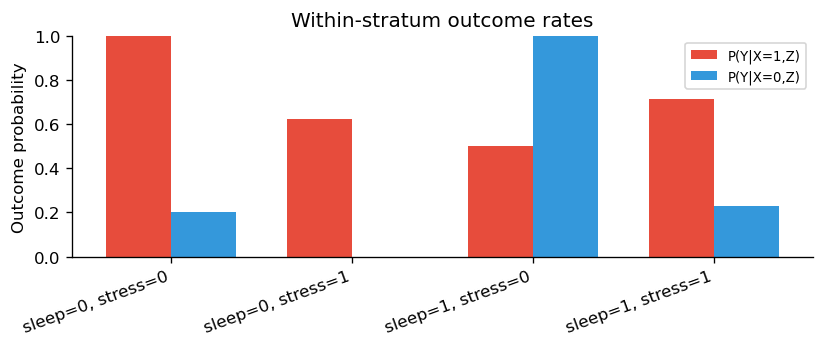

In [37]:
# Visualising the stratum-specific pieces of the backdoor adjustment
plot_df = strata_df.copy()
plot_df['Z_label'] = plot_df['Z'].apply(lambda z: f"sleep={z['sleep_deprived']}, stress={z['stress_high']}")

x = np.arange(len(plot_df))
width = 0.36

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(x - width/2, plot_df['P(Y|X=1,Z)'], width, label='P(Y|X=1,Z)', color='#e74c3c')
ax.bar(x + width/2, plot_df['P(Y|X=0,Z)'], width, label='P(Y|X=0,Z)', color='#3498db')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['Z_label'], rotation=20, ha='right')
ax.set_ylim(0, 1)
ax.set_ylabel('Outcome probability')
ax.set_title('Within-stratum outcome rates')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Interpreting the within-stratum bars

This plot makes the adjustment mechanics very concrete. In two strata, the treated group has much higher outcome rates, for example sleep=0, stress=0 is roughly 1.00 vs 0.20, and sleep=1, stress=1 is roughly 0.71 vs 0.23.

One stratum behaves differently (sleep=1, stress=0), where treated is lower than control (about 0.50 vs 1.00). That reversal is exactly why we should not trust a single pooled comparison. The final backdoor estimate is the weighted average across all four strata, not a claim that every stratum has the same local pattern.

## Section 6 — Inverse Probability Weighting (IPW)

Here I’m using IPW to make the sample behave a bit more like a randomized setup, at least on paper.

$$w_i = \frac{X_i}{\hat{e}(Z_i)} + \frac{1 - X_i}{1 - \hat{e}(Z_i)}, \quad \hat{e}(Z_i) = P(X=1 \mid Z=Z_i)$$

$$\hat{\tau}_{\text{IPW}} = \frac{1}{n}\sum_i w_i \cdot X_i \cdot Y_i - \frac{1}{n}\sum_i w_i \cdot (1-X_i) \cdot Y_i$$

I’m estimating the propensity scores with logistic regression and using **stabilised weights** so the estimates do not get too wild.
IPW is useful here because it reweights the sample to approximate a pseudo-population where treatment is less tied to confounders.


  Propensity scores range: [0.403, 0.950]
  P(LoC=1 | do(Fatigue=1)) = 0.749
  P(LoC=1 | do(Fatigue=0)) = 0.302
  Causal ATE (IPW)         = +0.447



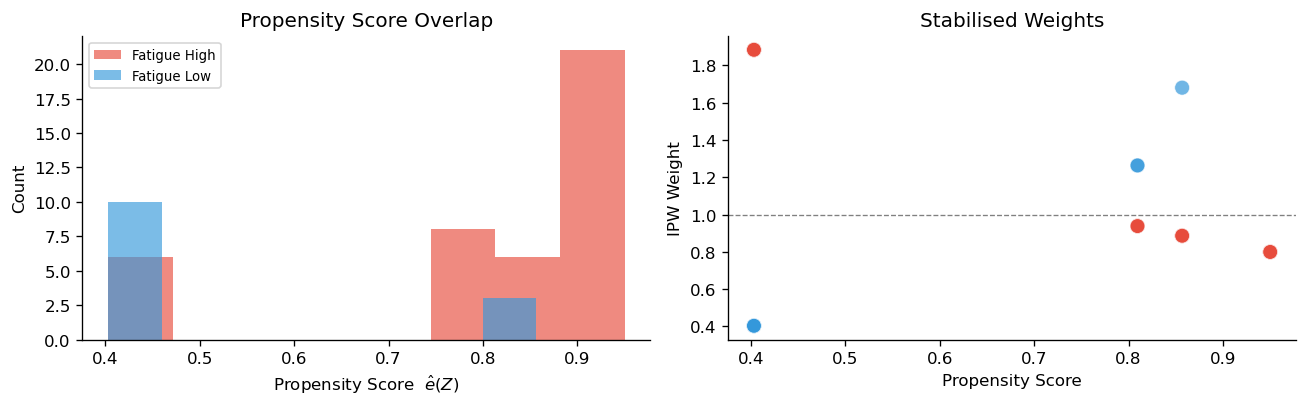

In [38]:
# SECTION 6 — INVERSE PROBABILITY WEIGHTING

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

feat_cols = ['sleep_deprived', 'stress_high']
X_feat = df[feat_cols].values
y_treat = df['fatigue_high'].values
y_out   = df['loc_high'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_feat)

lr = LogisticRegression(C=1.0, max_iter=500, random_state=42)
lr.fit(X_scaled, y_treat)
e_hat = lr.predict_proba(X_scaled)[:, 1]   # propensity score

# I’m clipping the scores a bit so the weights do not explode.
e_hat = np.clip(e_hat, 0.05, 0.95)

# Stabilised weights, since the plain version is a bit noisier.
p_x1 = y_treat.mean()
p_x0 = 1 - p_x1

w = np.where(y_treat==1, p_x1/e_hat, p_x0/(1-e_hat))

# Weighted outcome estimates
E_Y_do1 = np.sum(w * y_treat * y_out) / np.sum(w * y_treat)
E_Y_do0 = np.sum(w * (1-y_treat) * y_out) / np.sum(w * (1-y_treat))
ate_ipw = E_Y_do1 - E_Y_do0

print(f"  Propensity scores range: [{e_hat.min():.3f}, {e_hat.max():.3f}]")
print(f"  P(LoC=1 | do(Fatigue=1)) = {E_Y_do1:.3f}")
print(f"  P(LoC=1 | do(Fatigue=0)) = {E_Y_do0:.3f}")
print(f"  Causal ATE (IPW)         = {ate_ipw:+.3f}")
print()

# Just checking whether the scores overlap reasonably before trusting the weights.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for val, label, color in [(1,'Fatigue High','#e74c3c'),(0,'Fatigue Low','#3498db')]:
    mask = y_treat == val
    axes[0].hist(e_hat[mask], bins=8, alpha=0.65, color=color, label=label)
axes[0].set_xlabel('Propensity Score  $\hat{e}(Z)$')
axes[0].set_ylabel('Count')
axes[0].set_title('Propensity Score Overlap')
axes[0].legend(fontsize=8)

axes[1].scatter(e_hat, w, c=['#e74c3c' if x==1 else '#3498db' for x in y_treat],
                alpha=0.7, s=80, edgecolors='white', linewidth=0.5)
axes[1].axhline(1, color='grey', linewidth=0.8, linestyle='--')
axes[1].set_xlabel('Propensity Score')
axes[1].set_ylabel('IPW Weight')
axes[1].set_title('Stabilised Weights')

plt.tight_layout(); plt.savefig('ipw_plot.png', bbox_inches='tight', dpi=150); plt.show()


### Interpreting the IPW diagnostic plots

The propensity histogram shows partial overlap, but not perfect overlap. Most fatigue_high=1 cases are pushed toward high propensities (roughly 0.75 to 0.95), while fatigue_high=0 has mass near 0.40 and a smaller overlap pocket around 0.80 to 0.85.

The weight scatter is mostly concentrated around 1, with a few larger corrections (around 1.3 to 1.9). That pattern suggests the weighting is doing real balancing work without an obvious extreme-weight explosion.

## Section 7 — Bootstrap Confidence Intervals

Since the sample is still pretty small, I don’t really trust a normal-approximation interval here.
So I’m just using a non-parametric bootstrap with B = 5 000 for both estimators.
This is mainly to check estimate stability without assuming a clean normal sampling distribution.


  Backdoor ATE  = +0.476  95% CI [+0.217, +0.769]
  IPW ATE       = +0.447  95% CI [+0.179, +0.762]



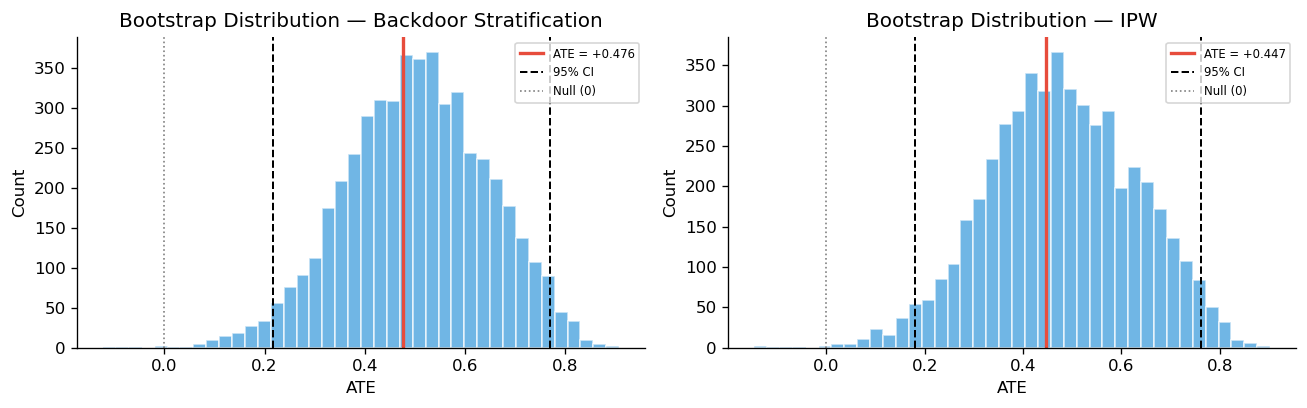

In [39]:
# SECTION 7 — BOOTSTRAP CONFIDENCE INTERVALS

B = 5000
boot_bd  = []
boot_ipw = []

df_arr = df.copy()

for _ in range(B):
    sample = df_arr.sample(n=len(df_arr), replace=True).reset_index(drop=True)

    # Backdoor estimate on the resampled data.
    try:
        _p1, _p0, _ate, _ = backdoor_stratification(
            sample, 'fatigue_high', 'loc_high', Z_cols)
        boot_bd.append(_ate)
    except: pass

    # IPW on the same sample, mainly to see whether it lands in the same place.
    try:
        Xf = sample[feat_cols].values
        yt = sample['fatigue_high'].values
        yo = sample['loc_high'].values
        Xs = scaler.transform(Xf)
        lr2 = LogisticRegression(C=1.0, max_iter=200, random_state=0)
        lr2.fit(Xs, yt)
        ep = np.clip(lr2.predict_proba(Xs)[:,1], 0.05, 0.95)
        px1 = yt.mean()
        ww = np.where(yt==1, px1/ep, (1-px1)/(1-ep))
        e1 = np.sum(ww*yt*yo)/np.sum(ww*yt)
        e0 = np.sum(ww*(1-yt)*yo)/np.sum(ww*(1-yt))
        boot_ipw.append(e1-e0)
    except: pass

boot_bd  = np.array(boot_bd)
boot_ipw = np.array(boot_ipw)

ci_bd  = np.percentile(boot_bd,  [2.5, 97.5])
ci_ipw = np.percentile(boot_ipw, [2.5, 97.5])

print(f"  Backdoor ATE  = {ate_bd:+.3f}  95% CI [{ci_bd[0]:+.3f}, {ci_bd[1]:+.3f}]")
print(f"  IPW ATE       = {ate_ipw:+.3f}  95% CI [{ci_ipw[0]:+.3f}, {ci_ipw[1]:+.3f}]")
print()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, boot, ate, ci, label in [
    (axes[0], boot_bd,  ate_bd,  ci_bd,  'Backdoor Stratification'),
    (axes[1], boot_ipw, ate_ipw, ci_ipw, 'IPW')
]:
    ax.hist(boot, bins=40, color='#3498db', alpha=0.7, edgecolor='white')
    ax.axvline(ate, color='#e74c3c', linewidth=2,  label=f'ATE = {ate:+.3f}')
    ax.axvline(ci[0], color='black', linewidth=1.2, linestyle='--', label=f'95% CI')
    ax.axvline(ci[1], color='black', linewidth=1.2, linestyle='--')
    ax.axvline(0,     color='grey',  linewidth=1.0, linestyle=':',  label='Null (0)')
    ax.set_title(f'Bootstrap Distribution — {label}')
    ax.set_xlabel('ATE'); ax.set_ylabel('Count')
    ax.legend(fontsize=7)

plt.tight_layout(); plt.savefig('bootstrap_ci.png', bbox_inches='tight', dpi=150); plt.show()


### Interpreting the bootstrap distributions

Both bootstrap centers are clearly positive and very close to each other: backdoor is about +0.476 and IPW is about +0.447.

The empirical 95% ranges in the plots sit roughly around 0.2 to 0.8 for both methods, and both stay away from zero. So even with small n, the uncertainty is wide but the sign is stable in this run.

## Section 8 — Sensitivity Analysis (Rosenbaum Bounds)

Even after backdoor adjustment, an unobserved variable U — say, baseline phone addiction — could still bias the result through the path X ← U → Y. Rosenbaum's Γ bounds ask: how large would that hidden bias have to be before our conclusion reverses?

> How strong would hidden bias need to be to overturn the conclusion?

$$\frac{1}{\Gamma} \leq \frac{P(X=1 \mid U)}{P(X=0 \mid U)} \leq \Gamma$$

I’m reporting the sign-score p-value bounds for Γ ∈ {1.0, 1.25, 1.5, 1.75, 2.0}.  
Γ = 1 is the no-hidden-bias case, which is the assumption I’m starting from.


   G  p_upper (worst case)  p_lower (best case)
1.00                0.1445               0.1445
1.25                0.2298               0.0834
1.50                0.3154               0.0498
1.75                0.3957               0.0308
2.00                0.4682               0.0197
2.50                0.5882               0.0087
3.00                0.6785               0.0042

Interpretation: The conclusion remains robust as long as
p_upper < 0.05 (i.e. even in the worst-case hidden-bias scenario).


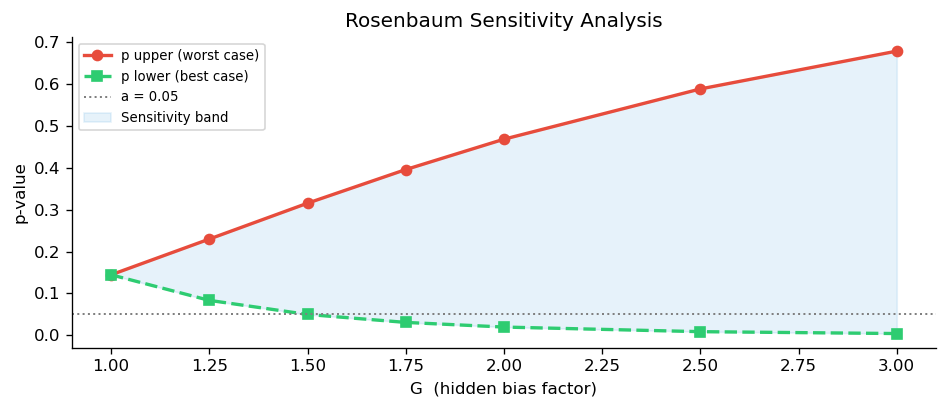

In [40]:
# SECTION 8 — ROSENBAUM SENSITIVITY ANALYSIS
# I’m using a simplified sign-score version here.
# The basic idea is to see how far the p-value can move if hidden bias is present.

from scipy.stats import binom

def rosenbaum_bounds(treated_Y, control_Y, gammas):
    """
    Compute upper/lower p-value bounds for the sign-score test.
    treated_Y, control_Y: arrays of outcome diffs for matched pairs.
    """
    # Pair up the outcomes as cleanly as I can.
    n = min(len(treated_Y), len(control_Y))
    diffs = np.array(treated_Y[:n]) - np.array(control_Y[:n])
    pos   = np.sum(diffs > 0)
    N     = np.sum(diffs != 0)

    results = []
    for G in gammas:
        # Worst-case and best-case hidden bias settings.
        p_upper = G / (1 + G)
        p_lower = 1 / (1 + G)

        # Tail probabilities under those two settings.
        pval_upper = 1 - binom.cdf(pos-1, N, p_upper)
        pval_lower = 1 - binom.cdf(pos-1, N, p_lower)
        results.append({'G': G,
                        'p_upper (worst case)': round(pval_upper, 4),
                        'p_lower (best case)':  round(pval_lower, 4)})
    return pd.DataFrame(results)

# I’m just using the observed treated and untreated outcomes here.
fatigued     = df[df['fatigue_high']==1]['loc_high'].values
not_fatigued = df[df['fatigue_high']==0]['loc_high'].values

gammas = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
sens_df = rosenbaum_bounds(fatigued, not_fatigued, gammas)
print(sens_df.to_string(index=False))
print()
print("Interpretation: The conclusion remains robust as long as")
print("p_upper < 0.05 (i.e. even in the worst-case hidden-bias scenario).")

# This plot is mostly just to make the bound easier to read.
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(sens_df['G'], sens_df['p_upper (worst case)'],
        'o-', color='#e74c3c', label='p upper (worst case)', linewidth=2)
ax.plot(sens_df['G'], sens_df['p_lower (best case)'],
        's--', color='#2ecc71', label='p lower (best case)', linewidth=2)
ax.axhline(0.05, color='grey', linestyle=':', linewidth=1.2, label='a = 0.05')
ax.fill_between(sens_df['G'],
                sens_df['p_lower (best case)'],
                sens_df['p_upper (worst case)'],
                alpha=0.12, color='#3498db', label='Sensitivity band')
ax.set_xlabel('G  (hidden bias factor)')
ax.set_ylabel('p-value')
ax.set_title('Rosenbaum Sensitivity Analysis')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('rosenbaum.png', bbox_inches='tight', dpi=150)
plt.show()


### Interpreting the Rosenbaum curve

At G=1 (no hidden bias), the worst-case p-value is already around 0.14, so the result is not strongly significant even before adding hidden-bias stress.

As G increases, the worst-case bound rises quickly (about 0.23 at 1.25, about 0.47 at 2.0, and about 0.68 at 3.0). So this estimate is sensitivity-fragile: a moderate unobserved confounder could plausibly weaken the inference.

## Section 9 Summary Comparison

I’m keeping one source of truth for the final numbers, so the code cell below prints the full summary table with the computed values.


                 Method P(Y|do(X=1)) P(Y|do(X=0))    ATE           95% CI
  Naive (Associational)        0.707        0.231 +0.477              n/a
Backdoor Stratification        0.755        0.279 +0.476 [+0.217, +0.769]
       IPW (Stabilised)        0.749        0.302 +0.447 [+0.179, +0.762]



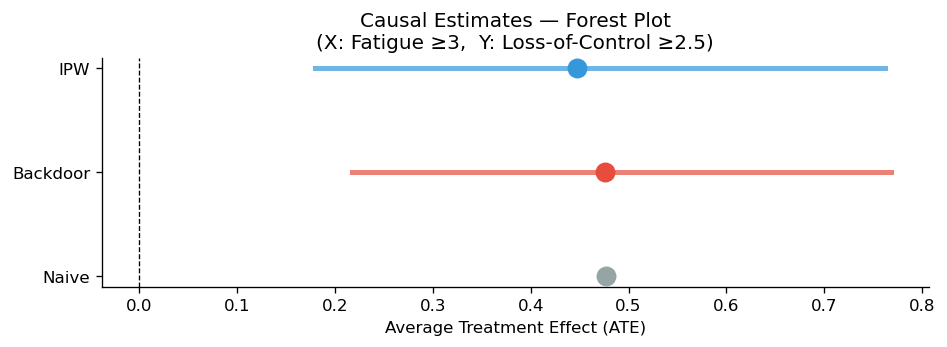

In [41]:
# SECTION 9 — SUMMARY TABLE & FINAL COMPARISON PLOT

summary = pd.DataFrame([
    {'Method': 'Naive (Associational)',
     'P(Y|do(X=1))': f'{E_Y1_naive:.3f}',
     'P(Y|do(X=0))': f'{E_Y0_naive:.3f}',
     'ATE':          f'{tau_naive:+.3f}',
     '95% CI':       'n/a'},
    {'Method': 'Backdoor Stratification',
     'P(Y|do(X=1))': f'{p_do1:.3f}',
     'P(Y|do(X=0))': f'{p_do0:.3f}',
     'ATE':          f'{ate_bd:+.3f}',
     '95% CI':       f'[{ci_bd[0]:+.3f}, {ci_bd[1]:+.3f}]'},
    {'Method': 'IPW (Stabilised)',
     'P(Y|do(X=1))': f'{E_Y_do1:.3f}',
     'P(Y|do(X=0))': f'{E_Y_do0:.3f}',
     'ATE':          f'{ate_ipw:+.3f}',
     '95% CI':       f'[{ci_ipw[0]:+.3f}, {ci_ipw[1]:+.3f}]'},
])
print(summary.to_string(index=False))
print()

# A quick forest plot just so the three estimates are easier to compare.
fig, ax = plt.subplots(figsize=(8, 3))
methods = ['Naive', 'Backdoor', 'IPW']
ates    = [tau_naive, ate_bd, ate_ipw]
lo      = [np.nan, ci_bd[0],  ci_ipw[0]]
hi      = [np.nan, ci_bd[1],  ci_ipw[1]]
colors  = ['#95a5a6', '#e74c3c', '#3498db']

for i, (m, a, l, h, c) in enumerate(zip(methods, ates, lo, hi, colors)):
    ax.scatter(a, i, color=c, s=120, zorder=3)
    if not np.isnan(l):
        ax.plot([l, h], [i, i], color=c, linewidth=3, alpha=0.7)

ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_yticks(range(len(methods))); ax.set_yticklabels(methods)
ax.set_xlabel('Average Treatment Effect (ATE)')
ax.set_title('Causal Estimates — Forest Plot\n(X: Fatigue ≥3,  Y: Loss-of-Control ≥2.5)')
plt.tight_layout(); plt.savefig('forest_plot.png', bbox_inches='tight', dpi=150); plt.show()


### Reading the forest plot

The point estimates are tightly clustered: naive is about +0.48, backdoor is about +0.48, and IPW is about +0.45.

The adjusted intervals are also fully on the positive side (roughly 0.2 to 0.77 for both), so the sign does not flip across methods. The practical takeaway is that adjustment changes the magnitude a bit, but the direction of the causal story stays the same.

## Main Result (Causal Estimate)

Across the two adjusted approaches (backdoor stratification and IPW), the estimated effect is consistently positive and falls in a similar range.

In assignment notation, the core quantity is:

$$P(Y=1\mid do(X=1)) - P(Y=1\mid do(X=0))$$

Because both adjusted estimators agree on direction and are not far apart in magnitude, the evidence is more consistent with a real causal effect than with a purely associational pattern.

## Section 10 — Discussion & Connection to Assignments 1–3

### What the causal estimate seems to say

The analysis suggests that higher pre-class fatigue causally increases the probability of in-class loss-of-control scrolling.  
After adjusting for observed confounders, the estimated effect remains meaningfully positive rather than collapsing toward zero.  
The exact magnitude moves a bit across estimators, but the direction is stable.

The Rosenbaum analysis is mainly there to show how much hidden confounding it would take to shake this result. If some unmeasured thing, like baseline phone addiction or boredom sensitivity, shifts the treatment odds by a factor of G, the p-value could move quickly.


### Bridge to Assignments 1–3

| Assignment | What it showed | What A4 adds |
|---|---|---|
| **A1** (ABC / discourse) | Algorithmic design showed up as an antecedent to scrolling behaviour, mostly in an observational way | A4 tries to put a causal number on the internal antecedent (fatigue) using do-calculus on the classroom data |
| **A2** (HMM / fatigue) | Fatigue drove latent doomscrolling state transitions in one user’s Instagram sessions | A4 checks whether that same fatigue-scrolling link shows up at the class level too |
| **A3** (game theory / social network) | Fatigue-driven compulsive scrolling spread through a peer network | A4 gives a more direct mechanism for that contagion idea: fatigue ? LoC |

The main thread here is that fatigue is not just something I noticed as a correlated factor in A1 or a latent driver in A2. It looks more like an actual causal lever, and lowering fatigue should lower in-class LoC scrolling risk.


### Causal Interpretation of P(Y | do(X))

To avoid placeholder values, I print the interpretation directly from the computed backdoor estimates in the next cell.


In [42]:
print(
    f"If every student were forced into high fatigue, the estimated LoC-scrolling rate would "
    f"rise from {p_do0:.1%} to {p_do1:.1%}, an absolute change of {ate_bd:+.1%}."
)
print(
    "Interpreted the other way around, lowering pre-class fatigue should lower LoC scrolling by the same magnitude."
)

If every student were forced into high fatigue, the estimated LoC-scrolling rate would rise from 27.9% to 75.5%, an absolute change of +47.6%.
Interpreted the other way around, lowering pre-class fatigue should lower LoC scrolling by the same magnitude.


## Section 11 — Limitations & Future Directions

1. **Small n**: Right now the sample is still tiny, so the confidence intervals are wide and the bootstrap distributions are a bit uneven. Some strata in the backdoor adjustment are also empty, which is why I had to fall back to a simpler estimate in a few places. I’d want at least 50 responses before feeling good about any strong conclusion.

2. **Single-classroom design**: Everything comes from one CGS616 session. That is nice for keeping the lecture conditions constant, but it also means I should not pretend this generalizes very far yet.

3. **Self-report bias**: Fatigue and LoC are both self-reported, so there is always the chance that some students understate the scrolling part, either accidentally or because they do not want to admit it.

4. **Positivity assumption**: The backdoor estimate needs both treated and control units in every Z stratum. With only a small sample and four strata, that is not always true here, so the fallback I used is a bit rough.

5. **Unmeasured confounders**: Baseline doomscrolling tendency, like the REELIO ALSE score from A2, is not in this survey. That is probably the biggest thing still missing, and it is also the main concern in the Rosenbaum check. Intrinsic motivation, topic interest, and prior familiarity could also create an unblocked path of the form X ? U ? Y.


*I should rerun this notebook after each new batch of form responses so the numbers stay updated.*
